In [ ]:
# Instalar o pacote watermark 

!pip install -q -U watermark 

In [39]:
# Importação da biblioteca para manipulação de dados em tabelas 
import pandas as pd 
# Importação da biblioteca NumPy para operações matemáticas e arrays 
import numpy as np 
# Importação da biblioteca Matplotlib para a geração de gráficos 
import matplotlib.pyplot as plt
# Importação da biblioteca Seaborn para a visualização de estatística de dados 
import seaborn as sns 
# Importação  da biblioteca random  para a geração de números aleatórios 
import random 
# Importação das classes datetime e timedelta para manipulação de datas e intervalos de tempo
from datetime import datetime, timedelta 
# Comando mágico do Jupyter Notebook que permite exibir gráficos diretamente no notebook 
%matplotlib inline

%reload_ext watermark
%watermark -a "Data Science Academy" 
%watermark --iversions
# Para instalar uma versão específica de um pacote, podemos fazer assim (por exemplo): 
!pip install -q pandas==2.3.1 

Author: Data Science Academy

matplotlib: 3.10.0
numpy     : 2.1.3
pandas    : 2.3.1
seaborn   : 0.13.2



----

In [9]:
# Definição para gerar dados fictícios de vendas 
def dsa_gera_dados_ficticios(num_registros=600):
    """Gera um DataFrame do Pandas com dados de vendas fictícios."""
    # Mensagem inicial indicando a quantidade de registros a serem gerados 
    print(f"\nIniciando a geração de {num_registros} registros de vendas...")
    #Dicionário com produtos, suas categorias e preços 
    produtos = {
        'Laptop Gamer': {'categoria': 'Eletrônicos', 'preco': 7500.00},
        'Mouse Vertical': {'categoria': 'Acessórios', 'preco': 250.00},
        'Teclado Mecânico': {'categoria': 'Acessórios', 'preco': 550.00},
        'Monitor Ultrawide': {'categoria': 'Eletrônicos', 'preco': 2800.00},
        'Cadeira Gamer': {'categoria': 'Móveis', 'preco': 1200.00},
        'Headset 7.1': {'categoria': 'Acessórios', 'preco': 800.00},
        'Placa de Vídeo': {'categoria': 'Hardware', 'preco': 4500.00},
        'SSD 1TB': {'categoria': 'Hardware', 'preco': 600.00}
    }
    # Cria uma lista apenas com nomes dos produtos 
    lista_produtos = list(produtos.keys())
    # Dicionário apenas com os nomes das cidades
    cidades_estados ={
        'São Paulo':'SP',
        'Rio de Janeiro':'RJ',
        'Belo Horizonte':'MG',
        'Porto Alegre':'RS',
        'Salvador':'BA', 
        'Curitiba':'PR',
        'Fortaleza':'CE'
    }
    #Cria uma lista apenas com os nomes das cidades 
    lista_cidades = list(cidades_estados.keys())
    # Lista de que armazenará os registrod de venda 
    dados_vendas = []
    # Define a data inicial dos pedidos 
    data_inicial = datetime(2026,1,1)
    # Loop oara gerar um registro de vendas 
    for i in range(num_registros): 
        # Seleciona aleatoriamente um produto 
        produto_nome = random.choice(lista_produtos)
        # Seleciona aleatoriamente uma cidade 
        cidade = random.choice(lista_cidades)
        # Gera uma quantidade de produtos vendidos entre 1 e 7 
        quantidade = np.random.randint(1,8)
        # Calvula a data do pedido a partir da data inicial 
        data_pedido = data_inicial + timedelta(days = int(i/5), hours = random.randint(0,23))
        # Se o produto for Mouse ou Teclado, aplicar o desconto aleatório de 10% 
        if produto_nome in ['Mouse Vertcal', 'Teclado Mecânico']: 
            preco_unitário = produtos [produto_nome]['preco'] * np.random.uniform(0.9,1.0)
        else: 
            preco_unitario = produtos [produto_nome]['preco']
        # Adicionando um registro de venda na lista 
        dados_vendas.append({
            'ID_Pedido': 1000 + i,
            'Data_Pedido': data_pedido,
            'Nome_Produto': produto_nome,
            'Categoria': produtos[produto_nome]['categoria'],
            'Preco_Unitario': round(preco_unitario, 2),
            'Quantidade': quantidade,
            'ID_Cliente': np.random.randint(100, 150),
            'Cidade': cidade,
            'Estado': cidades_estados[cidade]
        })
    
    # Mensagem final indicando que a geração terminou
    print("Geração de dados concluída.\n")

    # Retorna os dados no formato de DataFrame
    return pd.DataFrame(dados_vendas)
    

___

In [10]:
# Gera dadas chamando a função da célula anterior 
df_vendas = dsa_gera_dados_ficticios(500)


Iniciando a geração de 500 registros de vendas...
Geração de dados concluída.



In [11]:
type(df_vendas)

pandas.core.frame.DataFrame

In [12]:
# Shape 
df_vendas.shape


(500, 9)

In [13]:
# Exibe as 5 primeiras linhas do DataFrame
df_vendas.head()

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado
0,1000,2026-01-01 12:00:00,Placa de Vídeo,Hardware,4500.0,4,106,Curitiba,PR
1,1001,2026-01-01 13:00:00,Monitor Ultrawide,Eletrônicos,2800.0,1,145,Porto Alegre,RS
2,1002,2026-01-01 11:00:00,Placa de Vídeo,Hardware,4500.0,2,122,Fortaleza,CE
3,1003,2026-01-01 21:00:00,SSD 1TB,Hardware,600.0,1,139,Rio de Janeiro,RJ
4,1004,2026-01-01 20:00:00,Headset 7.1,Acessórios,800.0,6,111,Rio de Janeiro,RJ


In [14]:
# Exibe as 5 últimas linhas do DataFrame
df_vendas.tail()

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado
495,1495,2026-04-10 05:00:00,Headset 7.1,Acessórios,800.0,2,101,Belo Horizonte,MG
496,1496,2026-04-10 04:00:00,Monitor Ultrawide,Eletrônicos,2800.0,3,148,São Paulo,SP
497,1497,2026-04-10 12:00:00,Mouse Vertical,Acessórios,250.0,7,109,Porto Alegre,RS
498,1498,2026-04-10 22:00:00,Cadeira Gamer,Móveis,1200.0,4,121,Belo Horizonte,MG
499,1499,2026-04-10 15:00:00,SSD 1TB,Hardware,600.0,1,147,Porto Alegre,RS


In [15]:
# Exibe informações gerais sobre o DataFrame (tipos de dados, valores não nulos)
df_vendas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   ID_Pedido       500 non-null    int64         
 1   Data_Pedido     500 non-null    datetime64[ns]
 2   Nome_Produto    500 non-null    object        
 3   Categoria       500 non-null    object        
 4   Preco_Unitario  500 non-null    float64       
 5   Quantidade      500 non-null    int64         
 6   ID_Cliente      500 non-null    int64         
 7   Cidade          500 non-null    object        
 8   Estado          500 non-null    object        
dtypes: datetime64[ns](1), float64(1), int64(3), object(4)
memory usage: 35.3+ KB


In [16]:
# Resumo estatístico
df_vendas.describe()

,ID_Pedido,Data_Pedido,Preco_Unitario,Quantidade,ID_Cliente
count,500.000000,500,500.000000,500.00000,500.000000
mean,1249.500000,2026-02-20 00:03:57.600000,2626.400000,3.89400,123.978000
min,1000.000000,2026-01-01 11:00:00,250.000000,1.00000,100.000000
25%,1124.750000,2026-01-25 23:30:00,600.000000,2.00000,112.000000
50%,1249.500000,2026-02-20 04:00:00,1200.000000,4.00000,123.000000
75%,1374.250000,2026-03-16 23:00:00,4500.000000,6.00000,136.000000
max,1499.000000,2026-04-10 22:00:00,7500.000000,7.00000,149.000000
std,144.481833,NaN,2572.687404,1.98258,14.351077


In [17]:
# Tipos de dados
df_vendas.dtypes

ID_Pedido                  int64
Data_Pedido       datetime64[ns]
Nome_Produto              object
Categoria                 object
Preco_Unitario           float64
Quantidade                 int64
ID_Cliente                 int64
Cidade                    object
Estado                    object
dtype: object

___

In [18]:
# Se a coluna 'Data_Pedido' não estiver como tipo datetime, precisamos fazer a conversão explícita  
# A coluna pode ser usada para análise atemporal
df_vendas['Data_Pedido'] = pd.to_datetime(df_vendas['Data_Pedido'])

In [19]:
# Engenharia de atributos 
# Criando uma coluna de 'Faturanmento' (preço x quantidade)
df_vendas['Faturamento'] = df_vendas['Preco_Unitario'] * df_vendas['Quantidade']

In [20]:
# Engenharia de atributos
# Usando uma função lambda para criar uma coluna de status de entrega
df_vendas['Status_Entrega'] = df_vendas['Estado'].apply(lambda estado: 'Rápida' if estado in ['SP', 'RJ', 'MG'] else 'Normal')

In [21]:
# Exibe informações gerais sobre o DataFrame (Tipos de dados, valores não nulos)
df_vendas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   ID_Pedido       500 non-null    int64         
 1   Data_Pedido     500 non-null    datetime64[ns]
 2   Nome_Produto    500 non-null    object        
 3   Categoria       500 non-null    object        
 4   Preco_Unitario  500 non-null    float64       
 5   Quantidade      500 non-null    int64         
 6   ID_Cliente      500 non-null    int64         
 7   Cidade          500 non-null    object        
 8   Estado          500 non-null    object        
 9   Faturamento     500 non-null    float64       
 10  Status_Entrega  500 non-null    object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(5)
memory usage: 43.1+ KB


In [22]:
# Exibe as 5 primeiras linhas novamente para verificar as nvas colunas 
df_vendas.head(10)

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado,Faturamento,Status_Entrega
0,1000,2026-01-01 12:00:00,Placa de Vídeo,Hardware,4500.0,4,106,Curitiba,PR,18000.0,Normal
1,1001,2026-01-01 13:00:00,Monitor Ultrawide,Eletrônicos,2800.0,1,145,Porto Alegre,RS,2800.0,Normal
2,1002,2026-01-01 11:00:00,Placa de Vídeo,Hardware,4500.0,2,122,Fortaleza,CE,9000.0,Normal
3,1003,2026-01-01 21:00:00,SSD 1TB,Hardware,600.0,1,139,Rio de Janeiro,RJ,600.0,Rápida
4,1004,2026-01-01 20:00:00,Headset 7.1,Acessórios,800.0,6,111,Rio de Janeiro,RJ,4800.0,Rápida
5,1005,2026-01-02 01:00:00,Cadeira Gamer,Móveis,1200.0,1,134,Fortaleza,CE,1200.0,Normal
6,1006,2026-01-02 03:00:00,SSD 1TB,Hardware,600.0,3,105,São Paulo,SP,1800.0,Rápida
7,1007,2026-01-02 01:00:00,Mouse Vertical,Acessórios,250.0,1,147,Salvador,BA,250.0,Normal
8,1008,2026-01-02 07:00:00,Cadeira Gamer,Móveis,1200.0,2,106,Rio de Janeiro,RJ,2400.0,Rápida
9,1009,2026-01-02 17:00:00,Headset 7.1,Acessórios,800.0,2,123,Curitiba,PR,1600.0,Normal


___

## Análise 1 - Top 10 Produtos Mais Vendidos
Quais os top 10 produtos mais vendidos?

In [23]:
# Agrupa por nome do produto, soma a quantidade e ordena para encontrar os mais vendidos
top_10_produtos = df_vendas.groupby('Nome_Produto')['Quantidade'].sum().sort_values(ascending = False).head(10)

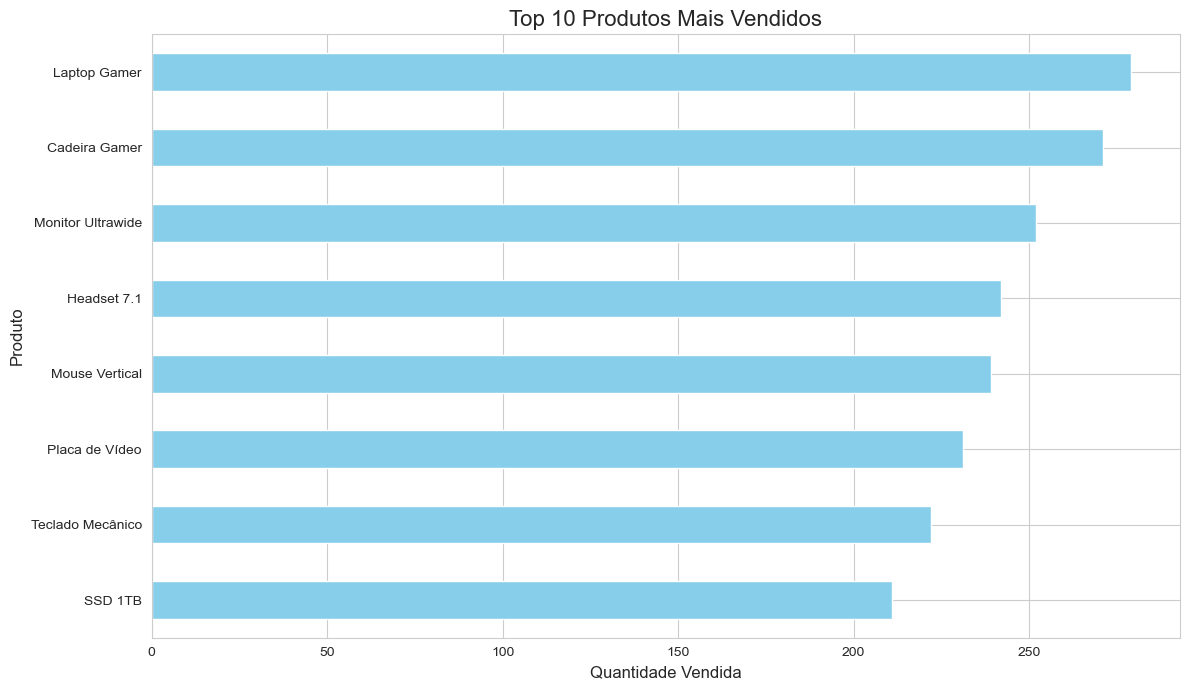

In [24]:
# Define um estilo para os gráficos 
sns.set_style("whitegrid")

# Cria a figura e os eixos 
plt.figure( figsize=(12, 7))

# Cria o gráfico de barras horizontais 
top_10_produtos.sort_values(ascending = True).plot(kind = 'barh', color = 'skyblue')

# Adiciona títulos e labels
plt.title('Top 10 Produtos Mais Vendidos', fontsize = 16)
plt.xlabel('Quantidade Vendida', fontsize = 12)
plt.ylabel('Produto', fontsize = 12)

# Exibe o gráfico 
plt.tight_layout()
plt.show()


## Análise 2 - Faturamento Mensal
Qual foi o faturamento mensal?

In [25]:
df_vendas.head()

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado,Faturamento,Status_Entrega
0,1000,2026-01-01 12:00:00,Placa de Vídeo,Hardware,4500.0,4,106,Curitiba,PR,18000.0,Normal
1,1001,2026-01-01 13:00:00,Monitor Ultrawide,Eletrônicos,2800.0,1,145,Porto Alegre,RS,2800.0,Normal
2,1002,2026-01-01 11:00:00,Placa de Vídeo,Hardware,4500.0,2,122,Fortaleza,CE,9000.0,Normal
3,1003,2026-01-01 21:00:00,SSD 1TB,Hardware,600.0,1,139,Rio de Janeiro,RJ,600.0,Rápida
4,1004,2026-01-01 20:00:00,Headset 7.1,Acessórios,800.0,6,111,Rio de Janeiro,RJ,4800.0,Rápida


In [26]:
# Cria uma coluna Mês para facilitar o agrupamento mensal 
df_vendas['Mes'] = df_vendas['Data_Pedido'].dt.to_period('M')

In [27]:
df_vendas.head()

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado,Faturamento,Status_Entrega,Mes
0,1000,2026-01-01 12:00:00,Placa de Vídeo,Hardware,4500.0,4,106,Curitiba,PR,18000.0,Normal,2026-01
1,1001,2026-01-01 13:00:00,Monitor Ultrawide,Eletrônicos,2800.0,1,145,Porto Alegre,RS,2800.0,Normal,2026-01
2,1002,2026-01-01 11:00:00,Placa de Vídeo,Hardware,4500.0,2,122,Fortaleza,CE,9000.0,Normal,2026-01
3,1003,2026-01-01 21:00:00,SSD 1TB,Hardware,600.0,1,139,Rio de Janeiro,RJ,600.0,Rápida,2026-01
4,1004,2026-01-01 20:00:00,Headset 7.1,Acessórios,800.0,6,111,Rio de Janeiro,RJ,4800.0,Rápida,2026-01


In [28]:
# Agrupa por mês e soma o faturamento 
faturamento_mensal = df_vendas.groupby('Mes')['Faturamento'].sum()

In [29]:
# Converte o índice para string para facilitar a plotagem no gráfico
faturamento_mensal.index = faturamento_mensal.index.strftime('%Y-%m')

In [30]:
# Formata para duas casas decimais
faturamento_mensal.map('R$ {:,.2f}'.format)

Mes
2026-01    R$ 1,530,050.00
2026-02    R$ 1,483,400.00
2026-03    R$ 1,801,000.00
2026-04      R$ 363,900.00
Name: Faturamento, dtype: object

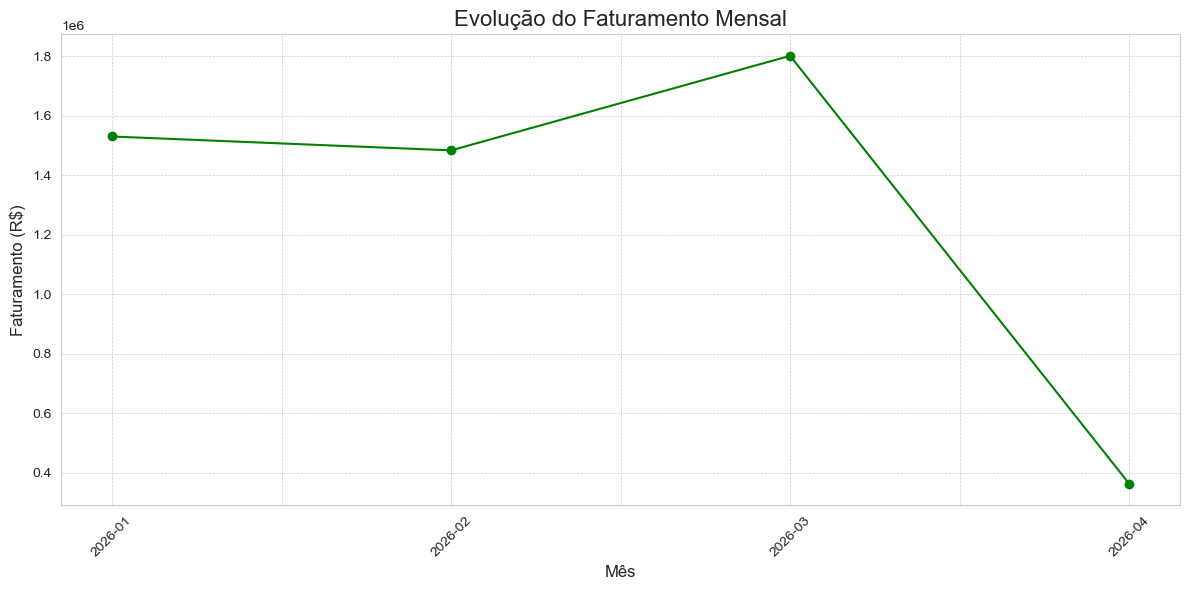

In [31]:
# Cria uma nova figura com tamanho de 12 por 6 polegadas
plt.figure(figsize = (12, 6))

# Plota os dados de faturamento mensal em formato de linha
faturamento_mensal.plot(kind = 'line', marker = 'o', linestyle = '-', color = 'green')

# Define o título do gráfico com fonte de tamanho 16
plt.title('Evolução do Faturamento Mensal', fontsize = 16)

# Define o rótulo do eixo X
plt.xlabel('Mês', fontsize = 12)

# Define o rótulo do eixo Y
plt.ylabel('Faturamento (R$)', fontsize = 12)

# Rotaciona os valores do eixo X em 45 graus para melhor visualização
plt.xticks(rotation = 45)

# Adiciona uma grade com estilo tracejado e linhas finas
plt.grid(True, which = 'both', linestyle = '--', linewidth = 0.5)

# Ajusta automaticamente os elementos para evitar sobreposição
plt.tight_layout()

# Exibe o gráfico
plt.show()

## Análise 3 - Vendas Por Estado
Qual o total de vendas por estado?

In [32]:
# Agrupa por estado e soma o faturamento
vendas_estado = df_vendas.groupby('Estado')['Faturamento'].sum().sort_values(ascending = False)

In [33]:
# Formata para duas casas decimais
vendas_estado.map('R$ {:,.2f}'.format)

Estado
MG    R$ 870,250.00
RJ    R$ 863,250.00
SP    R$ 773,150.00
RS    R$ 704,550.00
BA    R$ 689,600.00
PR    R$ 674,600.00
CE    R$ 602,950.00
Name: Faturamento, dtype: object

https://seaborn.pydata.org/generated/seaborn.color_palette.html

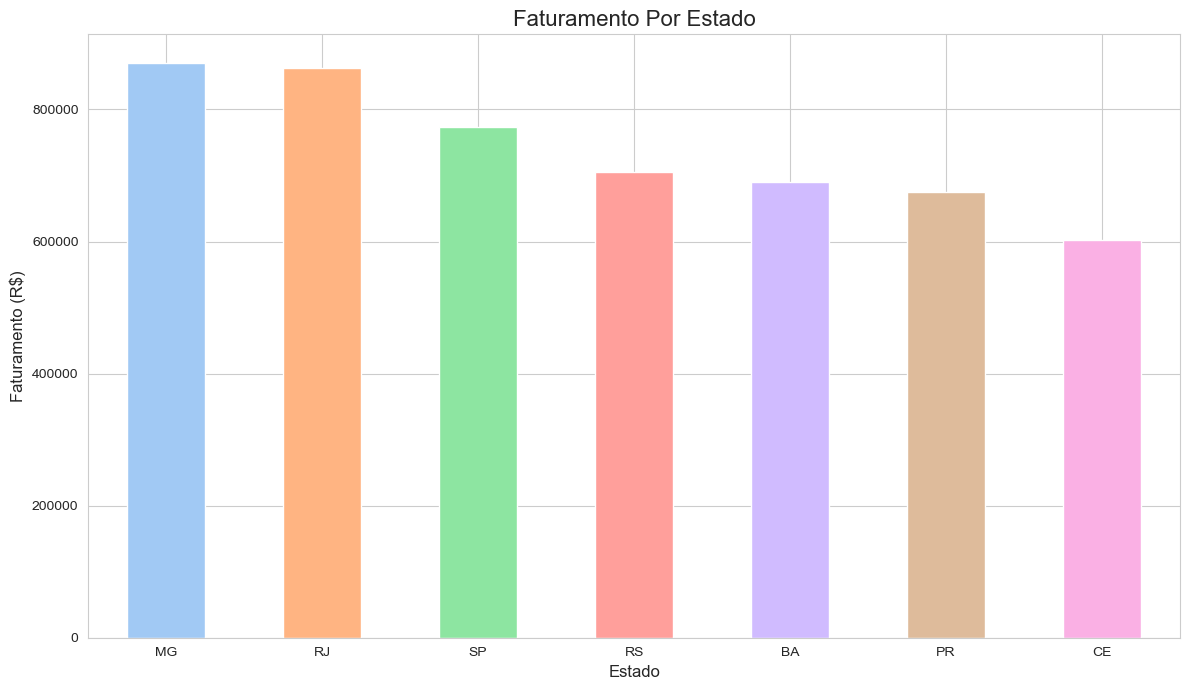

In [34]:

# Cria uma nova figura com tamanho de 12 por 7 polegadas
plt.figure(figsize = (12, 7))

# Plota os dados de faturamento por estado em formato de gráfico de barras
# Usando a paleta de cores "rocket" do Seaborn
vendas_estado.plot(kind = 'bar', color = sns.color_palette("pastel"))

# Define o título do gráfico com fonte de tamanho 16
plt.title('Faturamento Por Estado', fontsize = 16)

# Define o rótulo do eixo X
plt.xlabel('Estado', fontsize = 12)

# Define o rótulo do eixo Y
plt.ylabel('Faturamento (R$)', fontsize = 12)

# Mantém os rótulos do eixo X na horizontal (sem rotação)
plt.xticks(rotation = 0)

# Ajusta automaticamente os elementos do gráfico para evitar sobreposição
plt.tight_layout()

# Exibe o gráfico
plt.show()

 ## Análise 4 - Faturamento Por Categoria 
Qual o faturamento total por categoria?

In [36]:
# Agrupa por categoria, soma o faturamento e formata como moeda para melhor leitura 
faturamento_categoria = df_vendas.groupby('Categoria')['Faturamento'].sum().sort_values(ascending = False)

In [37]:
# O .map('{:,.2f}'.format) é opcional, mas deixa a visualização do número mais clara
faturamento_categoria.map('R$ {:,.2f}'.format)

Categoria
Eletrônicos    R$ 2,798,100.00
Hardware       R$ 1,166,100.00
Acessórios       R$ 888,950.00
Móveis           R$ 325,200.00
Name: Faturamento, dtype: object

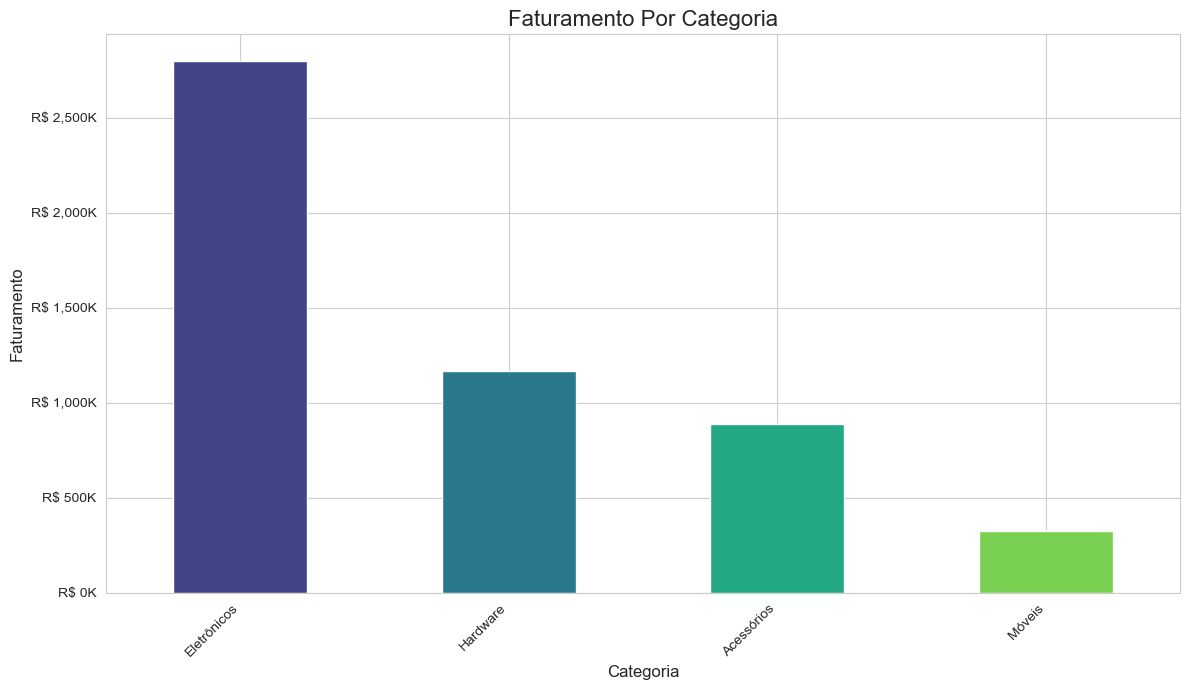

In [44]:
# Importa a função FuncFormatter para formatar os eixos
from matplotlib.ticker import FuncFormatter

# Ordena os dados para o gráfico ficar mais fácil de ler
faturamento_ordenado = faturamento_categoria.sort_values(ascending = False)

# Cria a Figura e os Eixos (ax) com plt.subplots()
# Isso nos dá mais controle sobre os elementos do gráfico.
fig, ax = plt.subplots(figsize = (12, 7))

# Esta função recebe um valor 'y' e o transforma em uma string no formato 'R$ XX K'
def formatador_milhares(y, pos):
    """Formata o valor em milhares (K) com o cifrão R$."""
    return f'R$ {y/1000:,.0f}K'

# Cria o objeto formatador
formatter = FuncFormatter(formatador_milhares)

# Aplica o formatador ao eixo Y (ax.yaxis)
ax.yaxis.set_major_formatter(formatter)

# Plota os dados usando o objeto 'ax'
faturamento_ordenado.plot(kind = 'bar', ax = ax, color = sns.color_palette("viridis", len(faturamento_ordenado)))

# Adiciona títulos e labels usando 'ax.set_...'
ax.set_title('Faturamento Por Categoria', fontsize = 16)
ax.set_xlabel('Categoria', fontsize = 12)
ax.set_ylabel('Faturamento', fontsize = 12)

# Ajusta a rotação dos rótulos do eixo X
plt.xticks(rotation = 45, ha = 'right')

# Garante que tudo fique bem ajustado na imagem final
plt.tight_layout()

# Exibe o gráfico
plt.show()